# Model-agnostic injection testing and verbal introspection

**Question.** When a concept direction is injected into the user's question turn,
does the model report that concept at the open quote more often than with
logit-lens directions, random directions, or no injection?

**Answer/status.** The saved outputs are an executed **offline smoke test** of a
random tiny Llama with identity Jacobians. J and logit directions agree, clean
controls agree across settings, and the analysis completes. These outputs check
the experiment; they do not establish introspection in a trained model.
Use `RUN_MODE="pretrained"` with a matching fitted lens for a trained run, or
`RUN_MODE="cache"` with this notebook's `results.json` for CPU-only reanalysis.

This adapts the [GPT-2 injection notebook](../../gpt2-xl/verbal_introspection/verbal_introspection.ipynb)
and the [model-agnostic bootstrap benchmark](../latent_bridge_v2_lens_benchmark_bootstrap.ipynb).
Model loading uses `jlens.from_hf`; no GPT-2 block names, fixed widths, or fixed
layer counts are assumed. The shared runner is in `jlens/introspection.py`.


## Method and interpretation

* **Prompt.** Use the dialogue and open-quote prefill in
  [the local protocol](../../../data/experiments/README.md#verbal-introspection).
  `auto` uses a checkpoint's chat template when present, with thinking disabled
  where the template supports that flag. Base models use plain `User:` /
  `Assistant:` turns. Character offsets locate the last user question; the
  displayed token span is the audit. BOS policy is explicit, never duplicated,
  and the readout cannot be truncated or moved onto a trailing special token.
* **Concepts.** Start from the same original 101 concepts on every model. A
  concept is eligible only if appending its exact surface after the quote
  preserves the prefill and adds one non-special token that decodes exactly to
  that surface. Show every exclusion; do not replace concepts or count missing
  coverage as failed retrieval. Set `DATASET_PATH` to
  `verbal-introspection-gpt2.json` to reproduce the GPT-2 noun replacements;
  `origin` summaries keep originals and added nouns separate.
* **Intervention.** At each band block, add the unit direction
  $v_{l,t}=J_l^T C(\gamma u_t)$ for a centering final norm, or
  $J_l^T(\gamma u_t)$ for RMSNorm. Norm behavior and effective gain are probed
  by the shared workspace helpers, including offset RMSNorm. Multiply the unit
  vector by `strength` and that trial's mean residual norm over patched positions
  at that layer. Earlier injections can change later norms. Logit directions
  use $J=I$; random directions use a fixed seeded vector per concept/layer.
* **Spans and bands.** The primary span is **user turn**, and the primary band is
  the depth fraction **[1/3, 5/6)**, corresponding to GPT-2 XL blocks 16–40.
  These choices precede inference; the other bands are exploratory. Fractional
  boundaries round to block indices, excluding the final block. **Whole prompt**
  excludes leading BOS and includes the readout position: it is an output-steering
  contrast, not evidence of a verbal report. No band/strength is selected by success.
* **Readout.** Capture the final block output and apply the model's public
  unembedding, so final norm runs once and logit transforms are retained.
  Rank the exact concept token in the actual next-token distribution. Exact
  ties break by token ID; rank 1 therefore agrees with the model's greedy token.
  `lexical_rank` retains the pre-softcap ordering as a diagnostic. This avoids
  the GPT-2 draft's optimistic tie convention on models with saturated logits.
* **Controls and examples.** One clean forward supplies strength 0 for every
  concept, span, band and arm. All positive trials are batched by span/band;
  each row shares the same prompt and needs no padding. Greedy examples batch
  the first three eligible concepts in J, logit and random arms at the minimum
  and maximum configured strengths. They re-run full prefixes for a fixed token
  horizon, without a KV cache or early EOS stopping. Only original prompt
  positions are patched; generated tokens are never directly injected.

The prefill already asserts **"Yes, I detect an injected thought."** This tests
concept reporting conditional on that prefill, not spontaneous detection,
yes/no calibration, or a 50/50 detection task. A positive whole-prompt result
can be direct steering; continuations reveal repetition and other artifacts.


## Repository setup (local or Colab)

Reuse a local checkout, including when opened from this nested folder. In Colab,
clone or fast-forward this fork and install into the active Python environment.
Errors stop setup. Run before importing `jlens`; restart a runtime that imported
an older checkout. Cache-only analysis in an existing checkout does not need
Hub access, model weights, lens files, or a tokenizer download.


In [1]:
import hashlib
import json
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ai360-project-school-j-lens/jacobian-lens-gpt2.git"
IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules

# Reuse a checkout when opened locally, including from a nested notebook folder.
local_repo = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "jlens" / "evaluation.py").is_file()),
    None,
)
REPO_DIR = local_repo or Path.cwd() / "jacobian-lens-gpt2"
if local_repo is not None:
    if IN_COLAB and os.environ.get("JLENS_INTROSPECTION_MODE") != "cache":
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
elif REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)

REPO = REPO_DIR.resolve()
if IN_COLAB and os.environ.get("JLENS_INTROSPECTION_MODE") != "cache":
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO)], check=True,
    )
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
if not (REPO / "jlens" / "introspection.py").is_file():
    raise RuntimeError("Update this checkout to the revision containing jlens/introspection.py.")
print(f"Repository ready: {REPO.name}")

Repository ready: jacobian-lens-gpt2


In [2]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import Markdown, display
from transformers import AutoConfig, AutoTokenizer

import jlens
from jlens.bootstrap import introspection_bootstrap
from jlens.introspection import (
    introspection_bands,
    introspection_concepts,
    load_introspection_cache,
    prepare_introspection_prompt,
    run_introspection,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 180)


## Configuration

`smoke` is completely offline and uses a local synthetic tokenizer, a random
four-block Llama, and identity Jacobians. `pretrained` loads the specified model
and an independently fitted lens; this notebook never fits on the concept set.
Set `MODEL_ID`, model revision, dtype, and matching local lens or Hub artifact.
The model lives on one device. Lower `BATCH_SIZE` for larger vocabularies/models;
only the last token is unembedded. `MODEL_CLASS` can select another Transformers
auto class for a supported wrapped text decoder.

The default dtype is float32 with no autocast. Change it explicitly to match the
fit and device. No fp32/autocast rank-equivalence claim is made. Fit metadata that
is unknown remains marked unknown; a compatible shape or a verified download
does not establish the scientific provenance of a lens.

`cache` reads the exact `EXISTING_TRIAL_CACHE` produced by this notebook and uses
its embedded prompt, concepts, model identity and inference settings. Current
model/data defaults are ignored. It never falls back to inference if a cache
is missing or invalid. The older GPT-2 CSV draft lacks the required provenance
and is not accepted as an interchangeable cache.


In [3]:
RUN_MODE = os.environ.get("JLENS_INTROSPECTION_MODE", "smoke")  # smoke, pretrained, cache
EXISTING_TRIAL_CACHE = os.environ.get("JLENS_INTROSPECTION_CACHE", "")
MODEL_ID = os.environ.get("JLENS_MODEL_ID", "openai-community/gpt2-xl")
MODEL_REVISION = os.environ.get("JLENS_MODEL_REVISION", "main")  # Resolved once to an immutable commit.
MODEL_CLASS = "AutoModelForCausalLM"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = getattr(torch, os.environ.get("JLENS_DTYPE", "float32"))
LENS_PATH = Path(os.environ.get(
    "JLENS_LENS_PATH", REPO / "runs/gpt2-xl-convergence/snapshot_lens_134.pt",
)).expanduser()
HUB_LENS_FILES = {
    "Qwen/Qwen3-4B": "qwen3-4b/jlens/Salesforce-wikitext/Qwen3-4B_jacobian_lens.pt",
    "Qwen/Qwen3-1.7B": "qwen3-1.7b/jlens/Salesforce-wikitext/Qwen3-1.7B_jacobian_lens.pt",
    "openai-community/gpt2": "gpt2-small/jlens/Salesforce-wikitext/gpt2_jacobian_lens.pt",
    "google/gemma-4-31B": "gemma-4-31b/jlens/Salesforce-wikitext/gemma-4-31B_jacobian_lens.pt",
    "google/gemma-4-E4B": "gemma-4-e4b/jlens/Salesforce-wikitext/gemma-4-E4B_jacobian_lens.pt",
    "Qwen/Qwen3.5-9B-Base": "qwen3.5-9b-pt/jlens/Salesforce-wikitext/Qwen3.5-9B-Base_jacobian_lens.pt",
    "Qwen/Qwen3.5-4B": "qwen3.5-4b/jlens/Salesforce-wikitext/Qwen3.5-4B_jacobian_lens_n1000.pt",
}
HUB_LENS = (
    dict(repo_id="neuronpedia/jacobian-lens", filename=HUB_LENS_FILES[MODEL_ID],
         revision="9fa267f841d62aa468dab5b9b38c3dc45a82d863")
    if MODEL_ID in HUB_LENS_FILES else None
)
LENS_SOURCE = "hub" if HUB_LENS and not os.environ.get("JLENS_LENS_PATH") else "local"
FIT_PROVENANCE = {
    "model_id": MODEL_ID, "model_revision": None, "dtype": "unknown",
    "corpus_mix": "unknown: fill from the independent fit manifest",
    "sequence_length": None, "dimension_batch_size": None,
}
# Use verbal-introspection-gpt2.json explicitly for the GPT-2 replacement nouns.
DATASET_PATH = Path(os.environ.get(
    "JLENS_INTROSPECTION_DATASET", REPO / "data/experiments/verbal-introspection.json",
)).expanduser()
PREFILL_KEY = "word"
PROMPT_STYLE = "auto"  # auto, plain, chat
BOS_POLICY = "auto"  # auto, prepend, none, tokenizer
MAX_SEQ_LEN = 512
BATCH_SIZE = int(os.environ.get("JLENS_BATCH_SIZE", "32"))
SEED = 0
STRENGTHS = [0.125, 0.25, 0.5, 1.0, 2.0, 4.0]  # Zero is the shared control pass.
BAND_FRACTIONS = {
    "early": [8 / 48, 16 / 48], "early middle": [16 / 48, 24 / 48],
    "middle": [24 / 48, 32 / 48], "late middle": [32 / 48, 40 / 48],
    "late": [40 / 48, 47 / 48], "wide middle": [16 / 48, 40 / 48],
}
PRIMARY_SPAN, PRIMARY_BAND = "user turn", "wide middle"
DEMO_CONCEPTS, DEMO_TOKENS = 3, 10
SMOKE_CONCEPTS = 8
CACHE_ROOT = Path(os.environ.get("JLENS_INTROSPECTION_ROOT", REPO / "runs/model-agnostic-introspection"))
FORCE_RECOMPUTE = False
if RUN_MODE not in {"smoke", "pretrained", "cache"}:
    raise ValueError("RUN_MODE must be smoke, pretrained, or cache")
if RUN_MODE == "smoke":
    STRENGTHS, DEMO_TOKENS = [0.25, 1.0, 4.0], 6
    BAND_FRACTIONS = {name: BAND_FRACTIONS[name] for name in ["early", PRIMARY_BAND]}


In [4]:
# Analysis settings do not enter the inference cache key.
BOOTSTRAP_OPTIONS = dict(
    n_resamples=int(os.environ.get("JLENS_BOOTSTRAP_RESAMPLES", "10000")),
    confidence=0.95, seed=0, batch_size=256,
)
COLORS = {"J": "#2a78d6", "logit": "#eb6834", "random": "#52514e", "control": "#999999"}


## Model identity, tokenization, and cache provenance

The inference key includes the resolved model commit/config, full tokenizer
serialization and chat template, rendered input IDs and spans, dataset bytes,
selected concepts and their eligibility audit, dtype/device, lens SHA-256 and
download receipt, fit metadata, seeds, batch settings, relevant implementation
files, package versions, and inference notebook code. Cache hits skip weight
loading and forwards. JSON caches and exported tables/figures live in ignored
`runs/`. Writes are atomic. Analysis has a separate manifest and directory, so
changing bootstrap settings or plots leaves the inference cache untouched.


In [5]:
def digest_json(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()


def digest_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)


NOTEBOOK_PATH = REPO / "notebooks/model_agnostic/verbal_introspection/model_agnostic_verbal_introspection.ipynb"
notebook_cells = json.loads(NOTEBOOK_PATH.read_text())["cells"]
INFERENCE_CELLS = {"repository-setup", "imports", "configuration", "cache-helpers", "identity", "run-or-restore"}
inference_code = ["".join(c["source"]) for c in notebook_cells
                  if c["cell_type"] == "code" and c["id"] in INFERENCE_CELLS]


In [6]:
# Clear previous in-memory state before any operation that could fail.
payload = manifest = config = tokenizer = RESOLVED_LENS_PATH = None
if RUN_MODE == "cache":
    if not EXISTING_TRIAL_CACHE:
        raise ValueError("Set EXISTING_TRIAL_CACHE to this notebook's exact results.json")
    CACHE_PATH = Path(EXISTING_TRIAL_CACHE).expanduser().resolve()
    payload = load_introspection_cache(CACHE_PATH)
    manifest = payload["manifest"]
    print("Cache-only: using saved metadata; all model, lens and tokenizer loading skipped.")
else:
    spec = json.loads(DATASET_PATH.read_text())
    if RUN_MODE == "smoke":
        from tokenizers import Tokenizer, models, pre_tokenizers
        from transformers import LlamaConfig, PreTrainedTokenizerFast

        splitter = pre_tokenizers.Whitespace()
        texts = [m["content"] for m in spec["intro_prompt"]]
        texts += [*spec["prefills"].values(), "User: Assistant: System:"]
        pieces = {piece for text in texts for piece, _ in splitter.pre_tokenize_str(text)}
        pieces.update(c["surface"] for c in spec["concepts"])
        vocab = {word: i for i, word in enumerate(["[UNK]", "[BOS]", "[PAD]", *sorted(pieces)])}
        backend = Tokenizer(models.WordLevel(vocab, unk_token="[UNK]"))
        backend.pre_tokenizer = splitter
        tokenizer = PreTrainedTokenizerFast(
            tokenizer_object=backend, unk_token="[UNK]", bos_token="[BOS]", pad_token="[PAD]",
        )
        config = LlamaConfig(
            vocab_size=len(tokenizer), hidden_size=32, intermediate_size=64,
            num_hidden_layers=4, num_attention_heads=4, num_key_value_heads=2,
            max_position_embeddings=MAX_SEQ_LEN + DEMO_TOKENS,
            bos_token_id=tokenizer.bos_token_id, eos_token_id=None, pad_token_id=tokenizer.pad_token_id,
        )
        run_model_id, resolved_revision = "offline/random-tiny-llama", f"seed-{SEED}"
        run_device, run_dtype = "cpu", torch.float32
        lens_provenance = {"source": "identity", "sha256_or_identity": "identity-v1", "fitting_provenance": "no fitting"}
        fit_provenance = {"method": "identity; no fitting", "dtype": "torch.float32", "corpus_mix": None,
                          "sequence_length": None, "dimension_batch_size": None}
    else:
        from huggingface_hub import HfApi

        from jlens.artifact_provenance import download_lens_artifact

        if FIT_PROVENANCE["model_id"] != MODEL_ID:
            raise ValueError("Fit model_id differs from MODEL_ID")
        resolved_revision = HfApi().model_info(MODEL_ID, revision=MODEL_REVISION).sha
        if not isinstance(resolved_revision, str) or not re.fullmatch(r"[0-9a-f]{40}", resolved_revision):
            raise ValueError("The Hub did not return an immutable model revision")
        if FIT_PROVENANCE["model_revision"] not in {None, resolved_revision}:
            raise ValueError("Fit model revision differs from the selected model")
        config = AutoConfig.from_pretrained(MODEL_ID, revision=resolved_revision)
        tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=resolved_revision, use_fast=True)
        if LENS_SOURCE == "hub":
            if not HUB_LENS:
                raise ValueError("Supply HUB_LENS for this model or select a local fitted lens")
            artifact = download_lens_artifact(**HUB_LENS)
            RESOLVED_LENS_PATH = artifact.verify()
            lens_provenance = {"source": "hub", **artifact.to_dict()}
        elif LENS_SOURCE == "local":
            RESOLVED_LENS_PATH = LENS_PATH.resolve()
            if not RESOLVED_LENS_PATH.is_file():
                raise FileNotFoundError(f"Set LENS_PATH to an independently fitted lens for {MODEL_ID}")
            lens_provenance = {"source": "local", "path": str(RESOLVED_LENS_PATH),
                               "sha256": digest_file(RESOLVED_LENS_PATH), "fitting_provenance": "user supplied; see fit metadata"}
        else:
            raise ValueError("LENS_SOURCE must be hub or local")
        run_model_id, run_device, run_dtype = MODEL_ID, DEVICE, DTYPE
        fit_provenance = FIT_PROVENANCE.copy()
    prompt = prepare_introspection_prompt(
        tokenizer, spec, prefill_key=PREFILL_KEY, prompt_style=PROMPT_STYLE,
        bos_policy=BOS_POLICY, max_length=MAX_SEQ_LEN,
    )
    coverage = introspection_concepts(tokenizer, spec, prompt)
    coverage["selected"] = coverage.supported
    if RUN_MODE == "smoke":
        selected_indices = coverage[coverage.supported].head(SMOKE_CONCEPTS).index
        coverage["selected"] = coverage.index.isin(selected_indices)
    concepts = coverage[coverage.selected].reset_index(drop=True)
    if concepts.empty:
        display(coverage)
        raise ValueError("No supported concepts; inspect the prompt and eligibility audit")
    text_config = config.get_text_config()
    bands = introspection_bands(text_config.num_hidden_layers, BAND_FRACTIONS)
    if PRIMARY_BAND not in bands or PRIMARY_SPAN not in prompt["spans"]:
        raise ValueError("Primary band/span must be configured before inference")
    limit = getattr(text_config, "max_position_embeddings", None)
    if limit and len(prompt["input_ids"]) + DEMO_TOKENS > limit:
        raise ValueError("Prompt plus greedy horizon exceeds the model context limit")
    implementation = [
        "jlens/introspection.py", "jlens/workspace.py", "jlens/hf.py", "jlens/readout.py",
        "jlens/hooks.py", "jlens/lens.py", "jlens/artifact_provenance.py",
    ]
    manifest = {
        "schema": "introspection-v1", "mode": RUN_MODE, "model": run_model_id,
        "revision": resolved_revision, "model_class": MODEL_CLASS, "config": config.to_dict(),
        "tokenizer": tokenizer.backend_tokenizer.to_str(), "special_tokens": tokenizer.special_tokens_map,
        "chat_template": tokenizer.chat_template, "prompt": prompt,
        "coverage": json.loads(coverage.to_json(orient="records")), "selected_concepts": concepts.concept.tolist(),
        "dataset": DATASET_PATH.name, "dataset_sha256": digest_file(DATASET_PATH),
        "dtype": str(run_dtype), "device": run_device, "seed": SEED, "batch_size": BATCH_SIZE,
        "bands": bands, "band_fractions": BAND_FRACTIONS, "strengths": STRENGTHS,
        "primary_span": PRIMARY_SPAN, "primary_band": PRIMARY_BAND,
        "demo_concepts": DEMO_CONCEPTS, "demo_tokens": DEMO_TOKENS, "max_seq_len": MAX_SEQ_LEN,
        "lens_artifact": {k: v for k, v in lens_provenance.items() if k != "path"}, "fit": fit_provenance,
        "implementation": {name: digest_file(REPO / name) for name in implementation},
        "notebook_code_sha256": digest_json(inference_code),
        "versions": {"torch": torch.__version__, "transformers": transformers.__version__,
                     "numpy": np.__version__, "pandas": pd.__version__},
        "matmul_precision": torch.get_float32_matmul_precision(),
        "scoring": "exact contextual token; distribution rank; ties by token ID; lexical rank diagnostic",
    }
    # Canonicalize config integer keys/tuples before hashing and comparing JSON.
    manifest = json.loads(json.dumps(manifest, allow_nan=False))
    CACHE_PATH = CACHE_ROOT / "inference" / digest_json(manifest)[:20] / "results.json"

SOURCE_MODE = manifest["mode"]
print(f"Source: {SOURCE_MODE}; model: {manifest['model']} @ {manifest['revision']}; dtype: {manifest['dtype']}")
print("Inference cache:", CACHE_PATH)
display(pd.Series(manifest["fit"], name="fit provenance").to_frame())


Source: smoke; model: offline/random-tiny-llama @ seed-0; dtype: torch.float32
Inference cache: /home/kitlix/projects/jacobian-lens-gpt2/runs/model-agnostic-introspection/inference/5eff9b26cf356b6fb433/results.json


,fit provenance
method,identity; no fitting
dtype,torch.float32
corpus_mix,NaN
sequence_length,NaN
dimension_batch_size,NaN


## Prompt, span, concept, and band audit

Inspect the decoded user turn before interpreting results. It must precede the
open quote and exclude the assistant prefill. In chat mode, generation scaffolding
may depend on the checkpoint; it is visible in the full rendered prompt below.
Coverage is separate from the smoke subset. Fractional bands can coincide on a
very shallow model; the resolved layer table is authoritative.


In [7]:
# Decoding uses only the serialized tokenizer, including in cache-only mode.
from tokenizers import Tokenizer

saved_tokenizer = Tokenizer.from_str(manifest["tokenizer"])
prompt = manifest["prompt"]
coverage = pd.DataFrame(manifest["coverage"])
print(prompt["text"])
print(f"\n{len(prompt['input_ids'])} tokens; rendering={prompt['style']}; BOS={prompt['bos_policy']}")
span_rows = []
for span, positions in prompt["spans"].items():
    span_rows.append(dict(
        span=span, first=positions[0], last=positions[-1], tokens=len(positions),
        includes_readout=len(prompt["input_ids"]) - 1 in positions,
        decoded=saved_tokenizer.decode([prompt["input_ids"][p] for p in positions], skip_special_tokens=False),
    ))
display(pd.DataFrame(span_rows).set_index("span"))
display(pd.DataFrame([
    dict(band=name, first=layers[0], stop_exclusive=layers[-1] + 1, blocks=len(layers),
         role="primary" if name == manifest["primary_band"] else "exploratory")
    for name, layers in manifest["bands"].items()
]).set_index("band"))
display(coverage.groupby(["origin", "reason"]).agg(candidates=("concept", "size"), selected=("selected", "sum")))
print(f"Supported: {coverage.supported.sum()}/{len(coverage)}; evaluated: {coverage.selected.sum()}")
display(coverage.loc[~coverage.supported, ["concept", "surface", "origin", "reason"]])


User: I am an interpretability researcher with access to your neural activations. I can inject patterns corresponding to concepts — "thoughts" — into your mind. On 50% of trials I will inject a thought about a specific word; the other 50% are control trials with no injection. Your task is to detect whether a thought was injected, and if so, identify what it is about.

Assistant: Understood.

User: Trial 1: Do you detect an injected thought? If so, what is the thought about?

Assistant: Yes, I detect an injected thought. The thought is about the word "

120 tokens; rendering=plain; BOS=prepend


,first,last,tokens,includes_readout,decoded
span,,,,,
user turn,84,102,19,False,"Trial 1 : Do you detect an injected thought ? If so , what is the thought about ?"
whole prompt,1,119,119,True,"User : I am an interpretability researcher with access to your neural activations . I can inject patterns corresponding to concepts — "" ..."


,first,stop_exclusive,blocks,role
band,,,,
early,1,2,1,exploratory
wide middle,1,3,2,primary


,,candidates,selected
origin,reason,,
original,supported,101,8


Supported: 101/101; evaluated: 8


,concept,surface,origin,reason


## Run or restore

Directions and random controls are built once and reused across strengths,
bands, spans, and demonstrations. The clean control is never recalculated per
concept. Norm scaling follows the GPT-2 batched injection notebook. The complete
paired trial grid, clean controls, and greedy examples are cached together.


In [8]:
results = demos = None
if RUN_MODE == "cache":
    print("Using saved trials and continuations; no model passes.")
elif CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    payload = load_introspection_cache(CACHE_PATH, expected_manifest=manifest)
    print("Restored matching cache; model weights, lens loading and forwards skipped.")
else:
    torch.manual_seed(SEED)
    loader = getattr(transformers, MODEL_CLASS)
    if RUN_MODE == "smoke":
        hf_model = loader.from_config(config).to(run_device).eval()
    else:
        hf_model = loader.from_pretrained(
            MODEL_ID, revision=resolved_revision, dtype=run_dtype,
        ).to(run_device).eval()
    model = jlens.from_hf(hf_model, tokenizer, force_bos=False)
    if RUN_MODE == "smoke":
        lens = jlens.JacobianLens(
            jacobians={layer: torch.eye(model.d_model) for layer in range(model.n_layers - 1)},
            n_prompts=0, d_model=model.d_model,
        )
    else:
        if digest_file(RESOLVED_LENS_PATH) != manifest["lens_artifact"]["sha256"]:
            raise ValueError("Lens bytes changed after manifest creation")
        lens = jlens.JacobianLens.load(str(RESOLVED_LENS_PATH))
    measured = run_introspection(
        model, lens, prompt, concepts, manifest["bands"], manifest["strengths"],
        primary_band=manifest["primary_band"], batch_size=BATCH_SIZE, seed=SEED,
        demo_concepts=DEMO_CONCEPTS, demo_tokens=DEMO_TOKENS, progress=True,
    )
    measured["diagnostics"]["lens_n_prompts"] = lens.n_prompts
    payload = {"manifest": manifest, **measured}
    atomic_json(CACHE_PATH, payload)
    # Validate what was saved, using the same path as an offline cache reanalysis.
    payload = load_introspection_cache(CACHE_PATH, expected_manifest=manifest)
    del model, hf_model, lens, measured
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results = pd.DataFrame(payload["trials"])
results["rr"] = 1.0 / results["rank"]
results["named"] = results["rank"].eq(1)
results["top5"] = results["rank"].le(5)
demos = pd.DataFrame(payload["demos"])
assert results["named"].equals(results.top1_id.eq(results.token_id))
if SOURCE_MODE == "smoke":
    paired = results.pivot(index=["span", "band", "strength", "concept"], columns="mode", values="rank")
    np.testing.assert_array_equal(paired.J, paired.logit)
    print("Smoke invariant: identity-J and logit ranks agree for every trial.")
print(len(results), "cached trials;", payload["diagnostics"]["forward_passes"], "original forward passes including demos")
display(pd.Series(payload["diagnostics"], name="diagnostics").to_frame())


Restored matching cache; model weights, lens loading and forwards skipped.
Smoke invariant: identity-J and logit ranks agree for every trial.
384 cached trials; 25 original forward passes including demos


,diagnostics
final_norm_centers,False
clean_top1_id,151
clean_top1,toilet
vocab_size,171
forward_passes,25
n_concepts,8
lens_n_prompts,0


## What the model actually says

Examples are fixed before inference: the first eligible concepts and the
configured minimum/maximum strengths, all at the primary band. Strength-zero
examples share the same prompt and are shown once per concept/span. Special
tokens and repeated words remain visible; the prefill's open quote is shown as
context. This is a fixed continuation horizon, not a fluency or full-answer score.


In [9]:
if demos.empty:
    print("Greedy examples were disabled in this source run.")
else:
    view = demos.assign(continuation=demos.continuation.map(lambda text: repr('"' + text)))
    display(view.set_index(["span", "concept", "mode", "strength"])[["continuation"]])


continuation
span         concept   mode   strength                                             
user turn    lightning J      0.00               '"toilet steel it photo gel medal'
             corner    J      0.00               '"toilet steel it photo gel medal'
             cinema    J      0.00               '"toilet steel it photo gel medal'
             lightning J      0.25               '"toilet steel it photo gel medal'
                              4.00        '"toilet steel picture ocean task System'
             corner    J      0.25             '"toilet steel picture ocean % case'
                              4.00             '"toilet steel picture ocean % case'
             cinema    J      0.25               '"toilet steel it photo gel medal'
                              4.00        '"toilet steel picture ocean task System'
             lightning logit  0.25               '"toilet steel it photo gel medal'
                              4.00        '"toilet steel picture ocean task System'
             corner    logit  0.25             '"toilet steel picture ocean % case'
                              4.00             '"toilet steel picture ocean % case'
             cinema    logit  0.25               '"toilet steel it photo gel medal'
                              4.00        '"toilet steel picture ocean task System'
             lightning random 0.25             '"toilet steel picture ocean % case'
                              4.00             '"toilet steel picture ocean % case'
             corner    random 0.25             '"toilet steel picture ocean % case'
                              4.00             '"toilet steel picture ocean % case'
             cinema    random 0.25               '"toilet steel it photo gel medal'
                              4.00               '"toilet steel it photo gel medal'
whole prompt lightning J      0.00               '"toilet steel it photo gel medal'
             corner    J      0.00               '"toilet steel it photo gel medal'
             cinema    J      0.00               '"toilet steel it photo gel medal'
             lightning J      0.25         '"lightning thumb bowl muscle judge gym'
                              4.00      '"lightning case ocean board squeeze [UNK]'
             corner    J      0.25        '"toilet steel picture detect if prophet'
                              4.00          '"corner pig toilet steel pasta narrow'
             cinema    J      0.25       '"custom photo gel painting weight ladder'
                              4.00                 '"cinema weight ladder if pig a'
             lightning logit  0.25         '"lightning thumb bowl muscle judge gym'
                              4.00      '"lightning case ocean board squeeze [UNK]'
             corner    logit  0.25        '"toilet steel picture detect if prophet'
                              4.00          '"corner pig toilet steel pasta narrow'
             cinema    logit  0.25       '"custom photo gel painting weight ladder'
                              4.00                 '"cinema weight ladder if pig a'
             lightning random 0.25         '"toilet steel picture case task System'
                              4.00          '"a muscle muscle muscle muscle muscle'
             corner    random 0.25          '"toilet steel picture ocean % picture'
                              4.00              '"I mind loss toilet steel picture'
             cinema    random 0.25            '"toilet steel it photo gel painting'
                              4.00        '"time beetle ease tape lightning beetle'

## Clean controls and ranking diagnostics

Controls are duplicated only to form paired comparisons. Count each concept
once, not once per band/arm. The no-injection top-1 token is the same for every
concept because the prompt is identical. A quiet concept control checks lexical
specificity; it does not undo the teacher-forced assertion that a thought was detected.


In [10]:
control_rows = results[results.strength.eq(0)]
assert control_rows.groupby("concept")[["rank", "lexical_rank", "top1_id"]].nunique().le(1).all().all()
controls = control_rows.drop_duplicates("concept")
display(controls.groupby("origin").agg(
    concepts=("concept", "size"), named=("named", "mean"), top5=("top5", "mean"),
    median_rank=("rank", "median"), mean_rr=("rr", "mean"),
))
print("Clean next token:", repr(payload["diagnostics"]["clean_top1"]))
rank_disagreements = results.assign(disagrees=results["rank"].ne(results.lexical_rank)).groupby(
    ["span", "mode"]
).disagrees.agg(["sum", "size", "mean"])
display(rank_disagreements.rename(columns={"sum": "distribution_lexical_rank_disagreements", "mean": "fraction"}))


,concepts,named,top5,median_rank,mean_rr
origin,,,,,
original,8,0.125,0.125,100.5,0.140466


Clean next token: 'toilet'


distribution_lexical_rank_disagreements  size  fraction
span         mode                                                           
user turn    J                                             0    64       0.0
             logit                                         0    64       0.0
             random                                        0    64       0.0
whole prompt J                                             0    64       0.0
             logit                                         0    64       0.0
             random                                        0    64       0.0

## Point estimates across all settings

Keep the protocol's **median reciprocal rank** curves separate from mean reciprocal
rank and report rates. Bootstrap intervals below apply to the **means** of `rr`,
`named`, and `top5`; they are not intervals for the median. All positive strengths
are retained, with no "best" strength selected on these data.


In [11]:
summary = results.groupby(["span", "band", "strength", "mode"]).agg(
    concepts=("concept", "size"), median_rr=("rr", "median"),
    mean_rr=("rr", "mean"), named=("named", "mean"), top5=("top5", "mean"),
).reset_index()
display(summary.pivot(index=["span", "band", "mode"], columns="strength", values="median_rr").round(4))
for metric in ["named", "top5"]:
    print(metric)
    display(summary.pivot(index=["span", "band", "mode"], columns="strength", values=metric).round(3))


strength                         0.00    0.25    1.00    4.00
span         band        mode                                
user turn    early       J       0.01  0.0100  0.0100  0.0101
                         logit   0.01  0.0100  0.0100  0.0101
                         random  0.01  0.0100  0.0100  0.0102
             wide middle J       0.01  0.0099  0.0099  0.0101
                         logit   0.01  0.0099  0.0099  0.0101
                         random  0.01  0.0101  0.0103  0.0108
whole prompt early       J       0.01  0.0385  1.0000  1.0000
                         logit   0.01  0.0385  1.0000  1.0000
                         random  0.01  0.0099  0.0185  0.0146
             wide middle J       0.01  0.1833  1.0000  1.0000
                         logit   0.01  0.1833  1.0000  1.0000
                         random  0.01  0.0111  0.0133  0.0120

named


strength                          0.00   0.25   1.00   4.00
span         band        mode                              
user turn    early       J       0.125  0.125  0.125  0.125
                         logit   0.125  0.125  0.125  0.125
                         random  0.125  0.125  0.125  0.125
             wide middle J       0.125  0.125  0.125  0.125
                         logit   0.125  0.125  0.125  0.125
                         random  0.125  0.125  0.125  0.125
whole prompt early       J       0.125  0.125  0.875  1.000
                         logit   0.125  0.125  0.875  1.000
                         random  0.125  0.125  0.125  0.000
             wide middle J       0.125  0.375  1.000  1.000
                         logit   0.125  0.375  1.000  1.000
                         random  0.125  0.125  0.000  0.000

top5


strength                          0.00   0.25   1.00   4.00
span         band        mode                              
user turn    early       J       0.125  0.125  0.125  0.125
                         logit   0.125  0.125  0.125  0.125
                         random  0.125  0.125  0.125  0.125
             wide middle J       0.125  0.125  0.125  0.125
                         logit   0.125  0.125  0.125  0.125
                         random  0.125  0.125  0.125  0.125
whole prompt early       J       0.125  0.250  1.000  1.000
                         logit   0.125  0.250  1.000  1.000
                         random  0.125  0.125  0.125  0.125
             wide middle J       0.125  0.500  1.000  1.000
                         logit   0.125  0.500  1.000  1.000
                         random  0.125  0.125  0.000  0.125

In [12]:
analysis_code = ["".join(c["source"]) for c in notebook_cells
                 if c["cell_type"] == "code" and c["id"] not in INFERENCE_CELLS]
analysis_manifest = {
    "schema": "introspection-analysis-v1", "source_manifest": manifest,
    "source_cache_sha256": digest_file(CACHE_PATH), "bootstrap": BOOTSTRAP_OPTIONS,
    "bootstrap_implementation_sha256": digest_file(REPO / "jlens/bootstrap.py"),
    "analysis_code_sha256": digest_json(analysis_code),
    "versions": {"numpy": np.__version__, "pandas": pd.__version__, "matplotlib": plt.matplotlib.__version__},
}
ANALYSIS_DIR = CACHE_ROOT / "analysis" / digest_json(analysis_manifest)[:20]
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
atomic_json(ANALYSIS_DIR / "manifest.json", analysis_manifest)
coverage.to_csv(ANALYSIS_DIR / "concept_coverage.csv", index=False)
summary.to_csv(ANALYSIS_DIR / "point_estimates.csv", index=False)
print("Derived analysis:", ANALYSIS_DIR)


Derived analysis: /home/kitlix/projects/jacobian-lens-gpt2/runs/model-agnostic-introspection/analysis/b361fbb6568e2a85752e


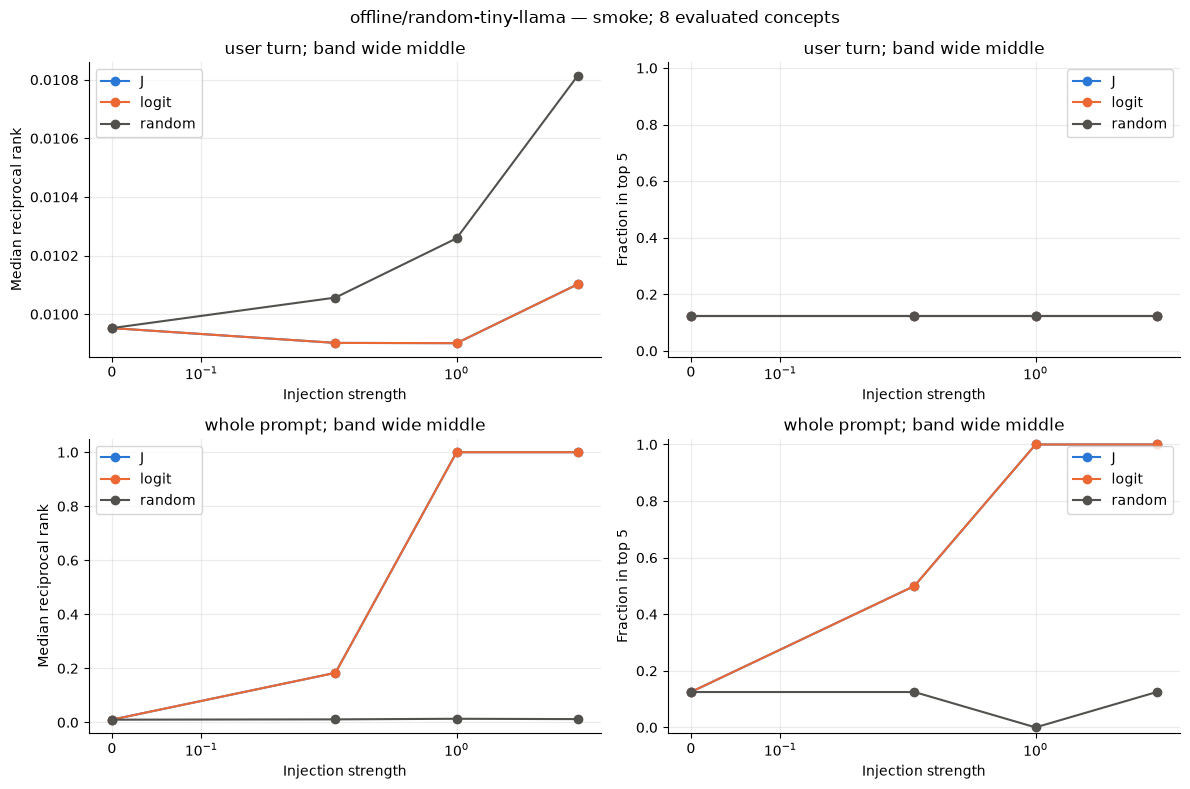

In [13]:
spans = list(manifest["prompt"]["spans"])
fig, axes = plt.subplots(len(spans), 2, figsize=(12, 4 * len(spans)), squeeze=False)
for row, span in enumerate(spans):
    table = summary[summary.span.eq(span) & summary.band.eq(manifest["primary_band"])]
    for mode in ["J", "logit", "random"]:
        line = table[table["mode"].eq(mode)].sort_values("strength")
        for ax, metric, label in zip(axes[row], ["median_rr", "top5"], ["Median reciprocal rank", "Fraction in top 5"], strict=True):
            ax.plot(line.strength, line[metric], marker="o", color=COLORS[mode], label=mode)
            ax.set_ylabel(label)
            ax.set_xlabel("Injection strength")
            ax.set_xscale("symlog", linthresh=min(manifest["strengths"]))
            ax.set_title(f"{span}; band {manifest['primary_band']}")
            ax.grid(alpha=0.25)
            ax.spines[["top", "right"]].set_visible(False)
    axes[row, 1].set_ylim(-0.02, 1.02)
    for ax in axes[row]:
        ax.legend()
fig.suptitle(f"{manifest['model']} — {SOURCE_MODE}; {len(controls)} evaluated concepts")
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "median_rr_and_top5.png", dpi=160)
plt.show()


## Paired concept bootstrap

Resample complete concepts with replacement, retaining J, logit, random and
strength-zero control arms together. Use 10,000 resamples and pointwise 95%
percentile intervals by default. Compute **J − logit**, **J − random**, and
**J − control** on the same draws. Concepts receive equal weight; separate
origin tables each resample their own concepts. Settings are evaluated independently.

Intervals condition on this model, lens, prompt, eligible concept set, random
direction seed, and setting. They do not cover fitting uncertainty, new prompts,
different concept distributions, seed variability, or dependence between semantically
related concepts. They do not correct for the many inspected bands and strengths.
A positive paired difference is a conditional report effect, not proof of
introspection. The whole-prompt contrast remains an output-steering diagnostic.

`degenerate`, `too_few_clusters`, and `no_supported_units` have **null interval
endpoints**. An all-zero arm has no bootstrap upper bound here and is not evidence
of a zero population rate. Null bands are left blank in the plots. Coverage counts
refer to the eligibility audit; bootstrap counts refer to selected eligible concepts.


In [14]:
ci_table = introspection_bootstrap(results, **BOOTSTRAP_OPTIONS)
ci_table["analysis_role"] = np.where(
    ci_table.span.eq(manifest["primary_span"]) & ci_table.band.eq(manifest["primary_band"]),
    "primary", "exploratory",
)
means = results[results.strength.gt(0)].groupby(["span", "band", "strength", "mode"])[["named", "top5", "rr"]].mean()
for row in ci_table[ci_table.statistic.eq("arm") & ci_table.arm.ne("control")].itertuples():
    np.testing.assert_allclose(row.estimate, means.loc[(row.span, row.band, row.strength, row.arm), row.metric], atol=1e-12)
if SOURCE_MODE == "smoke":
    identity_differences = ci_table[ci_table.statistic.eq("difference") & ci_table.reference.eq("logit")]
    assert identity_differences.estimate.eq(0).all()
    assert identity_differences.status.eq("degenerate").all()
ci_table.to_csv(ANALYSIS_DIR / "paired_bootstrap.csv", index=False)
primary = ci_table[ci_table.analysis_role.eq("primary")]
display(ci_table.status.value_counts().to_frame("intervals"))


def ci_view(table):
    label = table.arm.where(table.statistic.eq("arm"), table.arm + " − " + table.reference)
    fmt = "{:.3g}".format
    interval = table.estimate.map(fmt) + " [" + table.ci_low.map(fmt) + ", " + table.ci_high.map(fmt) + "]"
    cell = interval.where(table.status.eq("ok"), table.estimate.map(fmt) + " (" + table.status + ")")
    return table.assign(label=label, cell=cell).pivot(index="strength", columns="label", values="cell")


print(f"Primary setting: {manifest['primary_span']}, {manifest['primary_band']}; n={len(controls)} concepts")
for metric in ["named", "top5", "rr"]:
    print(f"{metric}: equal-concept mean and {100 * BOOTSTRAP_OPTIONS['confidence']:g}% pointwise interval")
    display(ci_view(primary[primary.metric.eq(metric)]))


,intervals
status,
ok,162
degenerate,90


Primary setting: user turn, wide middle; n=8 concepts
named: equal-concept mean and 95% pointwise interval


label,J,J − control,J − logit,J − random,control,logit,random
strength,,,,,,,
0.25,"0.125 [0, 0.375]",0 (degenerate),0 (degenerate),0 (degenerate),"0.125 [0, 0.375]","0.125 [0, 0.375]","0.125 [0, 0.375]"
1.00,"0.125 [0, 0.375]",0 (degenerate),0 (degenerate),0 (degenerate),"0.125 [0, 0.375]","0.125 [0, 0.375]","0.125 [0, 0.375]"
4.00,"0.125 [0, 0.375]",0 (degenerate),0 (degenerate),0 (degenerate),"0.125 [0, 0.375]","0.125 [0, 0.375]","0.125 [0, 0.375]"


top5: equal-concept mean and 95% pointwise interval


label,J,J − control,J − logit,J − random,control,logit,random
strength,,,,,,,
0.25,"0.125 [0, 0.375]",0 (degenerate),0 (degenerate),0 (degenerate),"0.125 [0, 0.375]","0.125 [0, 0.375]","0.125 [0, 0.375]"
1.00,"0.125 [0, 0.375]",0 (degenerate),0 (degenerate),0 (degenerate),"0.125 [0, 0.375]","0.125 [0, 0.375]","0.125 [0, 0.375]"
4.00,"0.125 [0, 0.375]",0 (degenerate),0 (degenerate),0 (degenerate),"0.125 [0, 0.375]","0.125 [0, 0.375]","0.125 [0, 0.375]"


rr: equal-concept mean and 95% pointwise interval


label,J,J − control,J − logit,J − random,control,logit,random
strength,,,,,,,
0.25,"0.14 [0.0108, 0.387]","-0.000742 [-0.00199, -4.59e-05]",0 (degenerate),"-0.000807 [-0.00204, -0.000115]","0.14 [0.0109, 0.388]","0.14 [0.0108, 0.387]","0.141 [0.011, 0.388]"
1.00,"0.138 [0.0102, 0.386]","-0.00225 [-0.0054, -0.000171]",0 (degenerate),"-0.00212 [-0.00458, -0.000407]","0.14 [0.0109, 0.388]","0.138 [0.0102, 0.386]","0.14 [0.0112, 0.388]"
4.00,"0.138 [0.0102, 0.385]","-0.00271 [-0.00696, -0.000118]",0 (degenerate),"-0.00173 [-0.00328, -0.000498]","0.14 [0.0109, 0.388]","0.138 [0.0102, 0.385]","0.139 [0.0114, 0.387]"


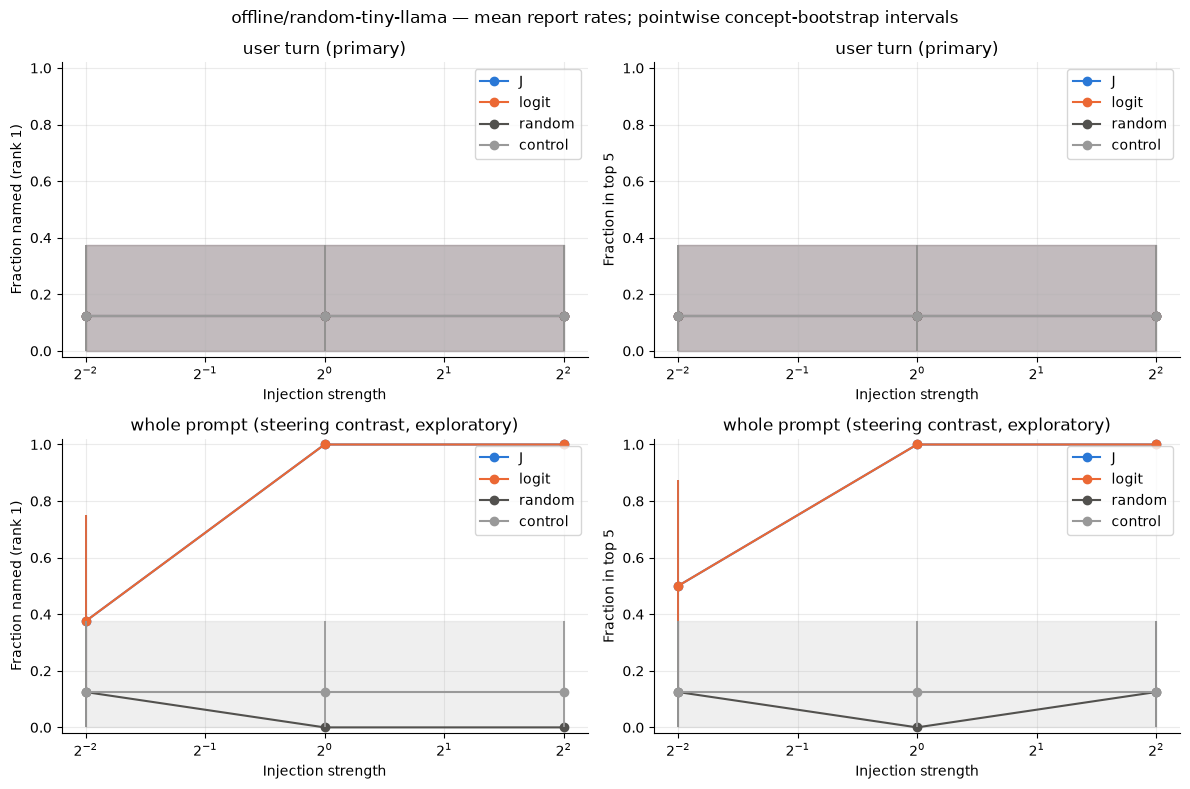

In [15]:
fig, axes = plt.subplots(len(spans), 2, figsize=(12, 4 * len(spans)), squeeze=False)
for row, span in enumerate(spans):
    table = ci_table[ci_table.span.eq(span) & ci_table.band.eq(manifest["primary_band"]) & ci_table.statistic.eq("arm")]
    for column, metric in enumerate(["named", "top5"]):
        ax = axes[row, column]
        for arm, color in COLORS.items():
            line = table[table.arm.eq(arm) & table.metric.eq(metric)].sort_values("strength")
            ok = line.status.eq("ok")
            ax.plot(line.strength, line.estimate, marker="o", color=color, label=arm)
            ax.fill_between(line.strength, line.ci_low.where(ok), line.ci_high.where(ok), color=color, alpha=0.15)
            ax.vlines(line.strength[ok], line.ci_low[ok], line.ci_high[ok], color=color, lw=1.3)
        ax.set_xscale("log", base=2)
        ax.set_ylim(-0.02, 1.02)
        ax.set_xlabel("Injection strength")
        ax.set_ylabel({"named": "Fraction named (rank 1)", "top5": "Fraction in top 5"}[metric])
        role = "primary" if span == manifest["primary_span"] else "steering contrast, exploratory"
        ax.set_title(f"{span} ({role})")
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend()
fig.suptitle(f"{manifest['model']} — mean report rates; pointwise concept-bootstrap intervals")
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "report_rates_bootstrap.png", dpi=160)
plt.show()


## Paired differences, origin groups, and concept examples

J − control measures the effect of the injection; J − random checks direction
specificity; J − logit compares the fitted direction with the unembedding direction.
Read these alongside the clean baseline, decoded continuations, and coverage.
All primary strengths appear below, including null-interval statuses.


,metric,strength,arm,reference,estimate,ci_low,ci_high,status,n_clusters
67,named,0.25,J,logit,0.000000,NaN,NaN,degenerate,8
68,named,0.25,J,random,0.000000,NaN,NaN,degenerate,8
69,named,0.25,J,control,0.000000,NaN,NaN,degenerate,8
74,top5,0.25,J,logit,0.000000,NaN,NaN,degenerate,8
75,top5,0.25,J,random,0.000000,NaN,NaN,degenerate,8
76,top5,0.25,J,control,0.000000,NaN,NaN,degenerate,8
81,rr,0.25,J,logit,0.000000,NaN,NaN,degenerate,8
82,rr,0.25,J,random,-0.000807,-0.002044,-0.000115,ok,8
83,rr,0.25,J,control,-0.000742,-0.001989,-0.000046,ok,8
88,named,1.00,J,logit,0.000000,NaN,NaN,degenerate,8


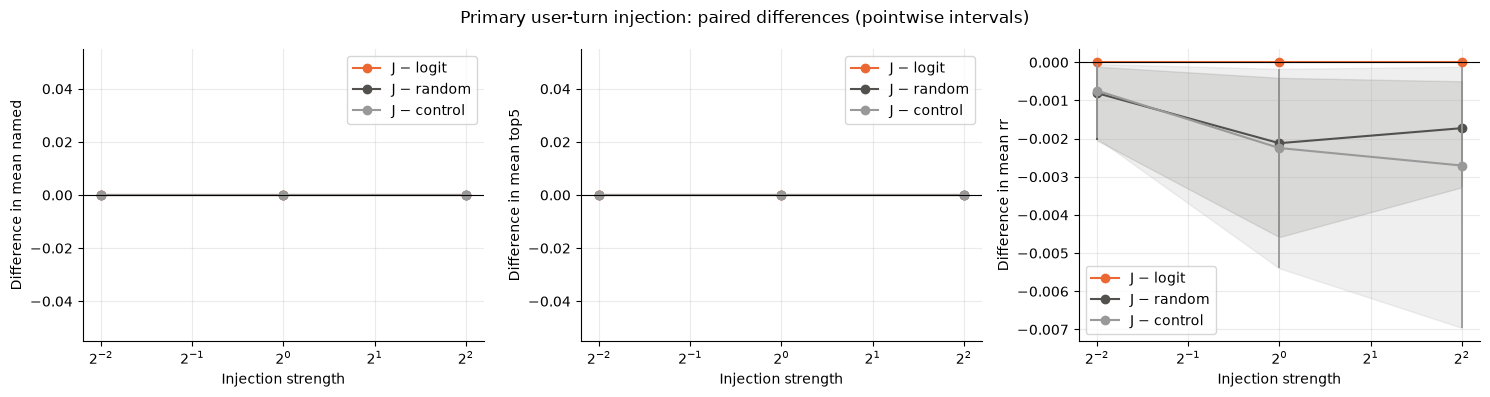

In [16]:
differences = primary[primary.statistic.eq("difference")]
display(differences[["metric", "strength", "arm", "reference", "estimate", "ci_low", "ci_high", "status", "n_clusters"]])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["named", "top5", "rr"], strict=True):
    for reference in ["logit", "random", "control"]:
        line = differences[differences.metric.eq(metric) & differences.reference.eq(reference)].sort_values("strength")
        ax.plot(line.strength, line.estimate, marker="o", color=COLORS[reference], label=f"J − {reference}")
        ax.fill_between(line.strength, line.ci_low, line.ci_high, color=COLORS[reference], alpha=0.15)
        ok = line.status.eq("ok")
        ax.vlines(line.strength[ok], line.ci_low[ok], line.ci_high[ok], color=COLORS[reference], lw=1.3)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xscale("log", base=2)
    ax.set_xlabel("Injection strength")
    ax.set_ylabel(f"Difference in mean {metric}")
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend()
fig.suptitle("Primary user-turn injection: paired differences (pointwise intervals)")
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "paired_differences.png", dpi=160)
plt.show()


In [17]:
primary_results = results[results.span.eq(manifest["primary_span"]) & results.band.eq(manifest["primary_band"])]
by_origin = introspection_bootstrap(
    primary_results, keys=["span", "band", "strength", "origin"], **BOOTSTRAP_OPTIONS,
)
by_origin.to_csv(ANALYSIS_DIR / "bootstrap_by_origin.csv", index=False)
display(by_origin[by_origin.statistic.eq("arm") & by_origin.metric.eq("top5")][
    ["origin", "strength", "arm", "estimate", "ci_low", "ci_high", "status", "n_clusters"]
])
# A predetermined diagnostic: every concept at the maximum configured strength.
concept_table = primary_results[primary_results.strength.eq(max(manifest["strengths"]))].pivot(
    index=["concept", "surface", "origin"], columns="mode", values=["rank", "top1"],
)
display(concept_table)
concept_table.to_csv(ANALYSIS_DIR / "concept_examples.csv")


,origin,strength,arm,estimate,ci_low,ci_high,status,n_clusters
7,original,0.25,J,0.125,0.0,0.375,ok,8
8,original,0.25,logit,0.125,0.0,0.375,ok,8
9,original,0.25,random,0.125,0.0,0.375,ok,8
10,original,0.25,control,0.125,0.0,0.375,ok,8
28,original,1.00,J,0.125,0.0,0.375,ok,8
29,original,1.00,logit,0.125,0.0,0.375,ok,8
30,original,1.00,random,0.125,0.0,0.375,ok,8
31,original,1.00,control,0.125,0.0,0.375,ok,8
49,original,4.00,J,0.125,0.0,0.375,ok,8
50,original,4.00,logit,0.125,0.0,0.375,ok,8


rank                 top1                
mode                            J logit random       J   logit  random
concept   surface   origin                                            
cinema    cinema    original   98    98     94  toilet  toilet  toilet
cook      cook      original   48    48     40  toilet  toilet   frame
corner    corner    original  100   100     91  toilet  toilet  toilet
lightning lightning original   28    28     24  toilet  toilet  toilet
ocean     ocean     original  119   119    117  toilet  toilet  toilet
summary   summary   original  112   112     98   frame   frame  toilet
toilet    toilet    original    1     1      1  toilet  toilet  toilet
tomb      tomb      original  125   125    113  toilet  toilet  toilet

## Conclusions

The statements below describe the active source run, including cache-only runs.
The scope stays fixed to the primary band/span; every configured strength is
reported. The smoke outputs verify execution only. Trained-model conclusions
must consider coverage, fit provenance, random/logit/clean controls, prompt
format, numerical precision, and the continuation examples together.


In [18]:
lines = []
if SOURCE_MODE == "smoke":
    lines.append("**Offline smoke only:** random tiny Llama with identity Jacobians. "
                 "J and logit ranks agree throughout; their paired differences are zero "
                 "with degenerate (null) intervals. This is a pipeline check, not a trained-model result.")
else:
    lines.append(f"**Model:** `{manifest['model']}` at `{manifest['revision']}`; dtype `{manifest['dtype']}`. "
                 "Unknown fitting provenance remains unverified.")
lines.append(f"**Coverage:** {int(coverage.supported.sum())}/{len(coverage)} concepts have an exact "
             f"single-token continuation; {len(controls)} are evaluated. Unsupported concepts are excluded, not failures.")
lines.append(f"**Clean baseline:** named {controls.named.mean():.1%}, top-5 {controls.top5.mean():.1%}; "
             f"next token `{payload['diagnostics']['clean_top1']!r}`.")
for row in primary[primary.statistic.eq("difference") & primary.metric.eq("named") & primary.reference.eq("random")].itertuples():
    interval = (f"[{row.ci_low:+.3f}, {row.ci_high:+.3f}]" if row.status == "ok" else f"no interval ({row.status})")
    lines.append(f"**Primary, strength {row.strength:g}:** J − random named-rate difference "
                 f"{row.estimate:+.3f}; {interval}. This is pointwise and conditional on the selected concepts.")
lines.append("The prefill asserts detection, so this experiment only tests the reported concept. "
             "Whole-prompt successes can be direct output steering. Inspect all paired controls "
             "and continuations before interpreting a user-turn effect; no favorable setting was selected.")
display(Markdown("\n\n".join(lines)))
assert digest_file(CACHE_PATH) == analysis_manifest["source_cache_sha256"]
print("Source inference cache unchanged by analysis.")
print("Tables, figures, and analysis manifest:", ANALYSIS_DIR)


**Offline smoke only:** random tiny Llama with identity Jacobians. J and logit ranks agree throughout; their paired differences are zero with degenerate (null) intervals. This is a pipeline check, not a trained-model result.

**Coverage:** 101/101 concepts have an exact single-token continuation; 8 are evaluated. Unsupported concepts are excluded, not failures.

**Clean baseline:** named 12.5%, top-5 12.5%; next token `'toilet'`.

**Primary, strength 0.25:** J − random named-rate difference +0.000; no interval (degenerate). This is pointwise and conditional on the selected concepts.

**Primary, strength 1:** J − random named-rate difference +0.000; no interval (degenerate). This is pointwise and conditional on the selected concepts.

**Primary, strength 4:** J − random named-rate difference +0.000; no interval (degenerate). This is pointwise and conditional on the selected concepts.

The prefill asserts detection, so this experiment only tests the reported concept. Whole-prompt successes can be direct output steering. Inspect all paired controls and continuations before interpreting a user-turn effect; no favorable setting was selected.

Source inference cache unchanged by analysis.
Tables, figures, and analysis manifest: /home/kitlix/projects/jacobian-lens-gpt2/runs/model-agnostic-introspection/analysis/b361fbb6568e2a85752e


The committed smoke run validates the shared model interface, identity-direction
equivalence, one-pass clean controls, cached continuations, and paired bootstrap
analysis. Its synthetic tokenizer coverage does not predict coverage on a real
checkpoint. It does not answer whether a pretrained model reports injected
concepts. Re-run with a matching independently fitted lens, then retain the
executed outputs and report the primary effects with coverage and controls.
